# Analyse des images — version française

[Source des données](https://www.kaggle.com/datasets/ibombonato/xray-body-images-in-png-unifesp-competion).

Objectif : reconnaître les parties du corps sur les radiographies.

## 1. Lire les données de train

Garder les identifiants et les catégories de `train_df.csv`. Retirer les espaces inutiles dans les catégories.

In [1]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path('../archive-2')
train = pd.read_csv(DATA_DIR / 'train_df.csv', usecols=['SOPInstanceUID', 'Target'])
train['Target'] = train['Target'].str.strip()

print('train :', train.shape)
print('Valeurs manquantes :', train.isna().sum().to_dict())
train.head()

train : (1738, 2)
Valeurs manquantes : {'SOPInstanceUID': 0, 'Target': 0}


,SOPInstanceUID,Target
0,1.2.826.0.1.3680043.8.498.10025629581362719970278200333618114258,0
1,1.2.826.0.1.3680043.8.498.10036150326276641158002573300029848125,15
2,1.2.826.0.1.3680043.8.498.10038426859954986240523417641213777162,12
3,1.2.826.0.1.3680043.8.498.10050991192143676483577217922037244257,14
4,1.2.826.0.1.3680043.8.498.10053309524595490852815579052225336016,3


## 2. Associer les images aux catégories

Créer les chemins, vérifier les fichiers et enregistrer le tableau préparé.

In [2]:
train_folder = DATA_DIR / 'images/train'
train['image_path'] = train['SOPInstanceUID'].apply(lambda uid: str(train_folder / f'{uid}-c.png'))

missing_train = 0
for path in train['image_path']:
    if not Path(path).is_file():
        missing_train += 1

print('Images manquantes :', missing_train)
assert missing_train == 0, 'Certains fichiers PNG sont manquants.'

CLEAN_DIR = Path('../data/cleaned')
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
train.to_csv(CLEAN_DIR / 'train.csv', index=False)

Images manquantes : 0


## 3. Compter les images par catégorie

Compter les images pour voir quelles catégories sont rares.

Compter chaque catégorie d’une image, car une image peut en avoir plusieurs.

**Catégories :**

| Code | Nom d’origine | Nom français |
| --- | --- | --- |
| 0 | Abdomen | Abdomen |
| 1 | Ankle | Cheville |
| 2 | Cervical Spine | Colonne cervicale |
| 3 | Chest | Thorax |
| 4 | Clavicles | Clavicules |
| 5 | Elbow | Coude |
| 6 | Feet | Pieds |
| 7 | Finger | Doigt |
| 8 | Forearm | Avant-bras |
| 9 | Hand | Main |
| 10 | Hip | Hanche |
| 11 | Knee | Genou |
| 12 | Lower Leg | Jambe |
| 13 | Lumbar Spine | Colonne lombaire |
| 14 | Others | Autres |
| 15 | Pelvis | Bassin |
| 16 | Shoulder | Épaule |
| 17 | Sinus | Sinus |
| 18 | Skull | Crâne |
| 19 | Thigh | Cuisse |
| 20 | Thoracic Spine | Colonne thoracique |
| 21 | Wrist | Poignet |

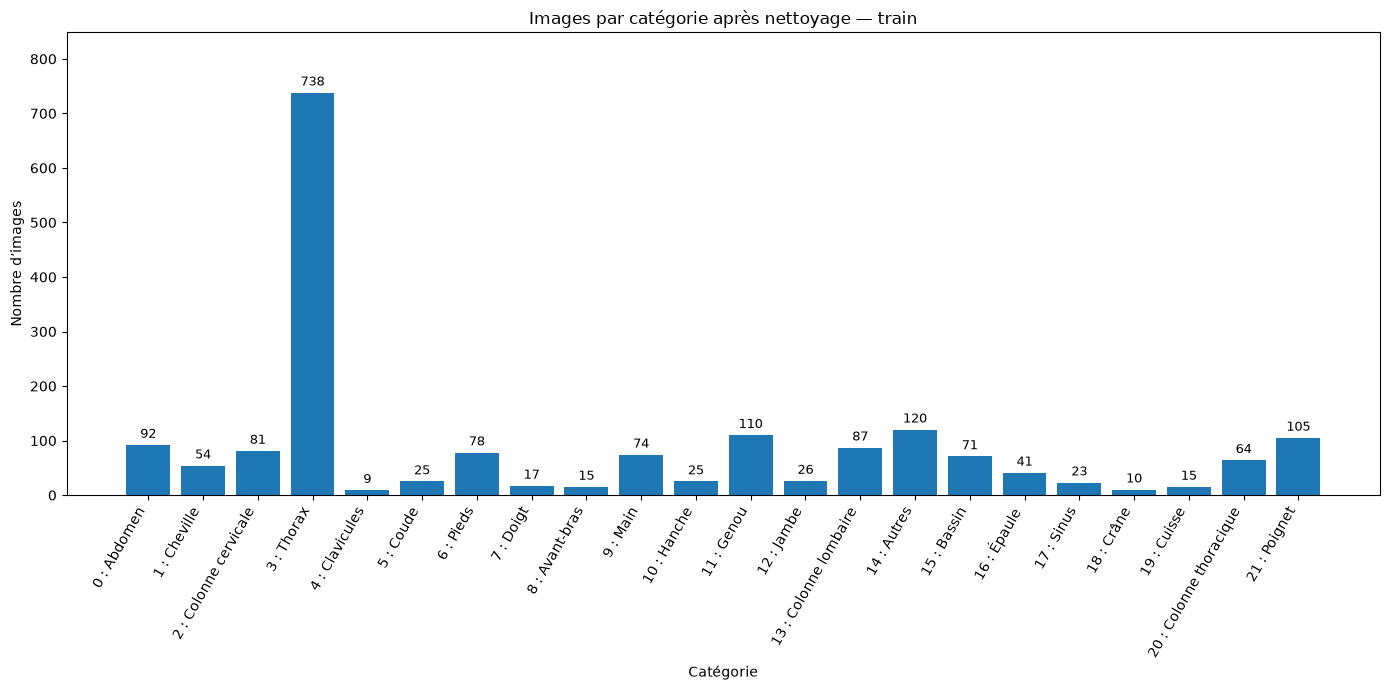

In [3]:
import matplotlib.pyplot as plt

category_names = {
    0: 'Abdomen',
    1: 'Cheville',
    2: 'Colonne cervicale',
    3: 'Thorax',
    4: 'Clavicules',
    5: 'Coude',
    6: 'Pieds',
    7: 'Doigt',
    8: 'Avant-bras',
    9: 'Main',
    10: 'Hanche',
    11: 'Genou',
    12: 'Jambe',
    13: 'Colonne lombaire',
    14: 'Autres',
    15: 'Bassin',
    16: 'Épaule',
    17: 'Sinus',
    18: 'Crâne',
    19: 'Cuisse',
    20: 'Colonne thoracique',
    21: 'Poignet',
}

categories = train['Target'].str.split().explode().astype(int)
category_counts = categories.value_counts().sort_index()

labels = [f'{code} : {category_names[code]}' for code in category_counts.index]

plt.figure(figsize=(14, 7))
bars = plt.bar(labels, category_counts.values)
plt.xticks(rotation=60, ha='right')
plt.bar_label(bars, padding=3, fontsize=9)
plt.xlabel('Catégorie')
plt.ylabel('Nombre d’images')
plt.title('Images par catégorie après nettoyage — train')
plt.ylim(0, category_counts.max() * 1.15)
plt.tight_layout()
plt.show()

Thorax : 738 images. Clavicules : 9 images.

Les nombres sont très différents : il faudra vérifier les résultats pour chaque catégorie.

## 4. Vérifier les images

Lire les images une seule fois. Vérifier leurs dimensions, leurs pixels et leurs canaux.

In [4]:
images = [plt.imread(path) for path in train['image_path']]

train_widths = []
train_heights = []
sizes = []
channels = []
pixel_types = []
pixel_mins = []
pixel_maxs = []
constant_images = 0

for image in images:
    train_widths.append(image.shape[1])
    train_heights.append(image.shape[0])
    sizes.append((image.shape[1], image.shape[0]))

    if image.ndim == 2:
        channels.append(1)
    else:
        channels.append(image.shape[2])

    pixel_types.append(str(image.dtype))
    pixel_mins.append(image.min())
    pixel_maxs.append(image.max())

    if image.min() == image.max():
        constant_images += 1

print('Images ouvertes :', len(sizes))
print('Largeur — train (min, max) :', min(train_widths), max(train_widths))
print('Hauteur — train (min, max) :', min(train_heights), max(train_heights))
print('Nombre de canaux :', set(channels))
print('Types des pixels :', set(pixel_types))
print('Valeurs des pixels (min, max) :', min(pixel_mins), max(pixel_maxs))
print('Images avec une seule valeur de pixel :', constant_images)

size_counts = pd.Series(sizes).value_counts()
size_counts.head(10)

Images ouvertes : 1738
Largeur — train (min, max) : 128 512
Hauteur — train (min, max) : 172 512
Nombre de canaux : {1}
Types des pixels : {'float32'}
Valeurs des pixels (min, max) : 0.0 1.0
Images avec une seule valeur de pixel : 0


(420, 512)    552
(512, 420)    551
(407, 512)    247
(380, 512)    146
(512, 407)    114
(512, 380)     57
(512, 512)     21
(300, 278)      3
(252, 192)      3
(300, 282)      3
Name: count, dtype: int64

Les 1 738 images s’ouvrent correctement. Elles sont en niveaux de gris, avec des pixels entre 0 et 1. Leurs tailles sont différentes.

Afficher six images pour observer leurs catégories et leurs dimensions.

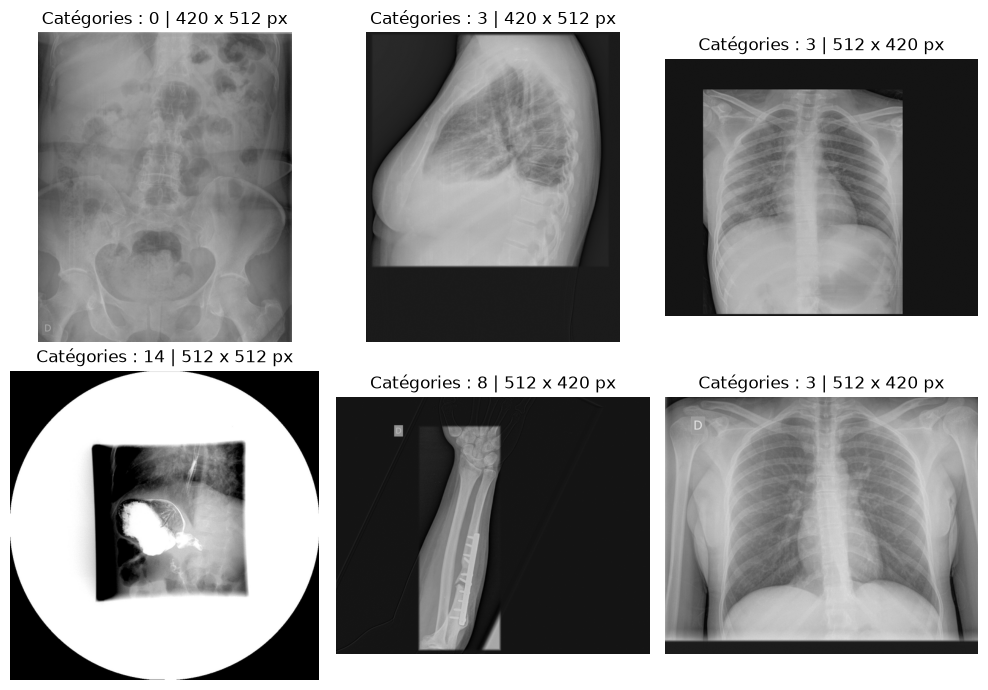

In [5]:
samples = train.sample(6, random_state=42)
plt.figure(figsize=(10, 7))

for i, row in enumerate(samples.itertuples()):
    image = images[row.Index]
    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap='gray', vmin=0, vmax=1)
    plt.title(f'Catégories : {row.Target} | {image.shape[1]} x {image.shape[0]} px')
    plt.axis('off')

plt.tight_layout()
plt.show()

## 5. Préparer train et la validation

Mettre les 22 catégories en 0 et 1. Séparer 80 % pour train et 20 % pour la validation, avec les mêmes images pour tous les essais.

In [6]:
import numpy as np
from sklearn.model_selection import train_test_split

y_train = np.zeros((len(train), 22), dtype=int)

for i, target in enumerate(train['Target']):
    for category in target.split():
        y_train[i, int(category)] = 1

images_fit, images_valid, y_fit, y_valid, _, validation = train_test_split(
    images, y_train, train, test_size=0.2, random_state=42
)

print('train :', len(images_fit), '| validation :', len(images_valid))

train : 1390 | validation : 348


## 6. Préparer les trois tailles

Ajouter des bordures noires pour garder les proportions. Réduire par blocs de 2 × 2 pixels pour obtenir la taille choisie.

Mettre les pixels sur une ligne pour Scikit-learn.

In [7]:
def prepare_images(images, size):
    X = np.zeros((len(images), size * size), dtype='float32')

    for i, image in enumerate(images):
        height, width = image.shape
        top = (512 - height) // 2
        left = (512 - width) // 2
        square = np.zeros((512, 512), dtype='float32')
        square[top:top + height, left:left + width] = image

        while square.shape[0] > size:
            half = square.shape[0] // 2
            square = square.reshape(half, 2, half, 2).mean(axis=(1, 3))

        X[i] = square.reshape(-1)

    return X

## 7. Comparer les tailles et les modèles

Tester 128, 256 et 512 avec kNN (3 voisins) et RandomForest (100 arbres).

Comparer les réponses entièrement correctes et le F1 moyen par catégorie. Un F1 proche de 1 est meilleur.

Enregistrer les modèles dans `models/` pour les utiliser dans Streamlit.

In [8]:
import joblib
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)

results = []

for size in [128, 256, 512]:
    X_fit = prepare_images(images_fit, size)
    X_valid = prepare_images(images_valid, size)

    models = {
        'kNN': KNeighborsClassifier(n_neighbors=3),
        'RandomForest': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
    }

    for name, model in models.items():
        model.fit(X_fit, y_fit)
        joblib.dump(model, MODELS_DIR / f'{name}_{size}.joblib')
        y_pred = model.predict(X_valid)
        results.append({
            'Taille': size,
            'Modèle': name,
            'Réponses entièrement correctes (%)': accuracy_score(y_valid, y_pred) * 100,
            'F1 moyen par catégorie': f1_score(y_valid, y_pred, average='macro', zero_division=0)
        })

validation[['SOPInstanceUID', 'Target']].to_csv(MODELS_DIR / 'validation.csv', index=False)

comparison = pd.DataFrame(results)
comparison.round(3)

,Taille,Modèle,Réponses entièrement correctes (%),F1 moyen par catégorie
0,128,kNN,65.230,0.514
1,128,RandomForest,53.448,0.319
2,256,kNN,65.230,0.512
3,256,RandomForest,54.310,0.324
4,512,kNN,64.943,0.512
5,512,RandomForest,52.586,0.301


**Résultat :** kNN en 128 × 128 obtient le meilleur F1 (0.514) sur cette validation. Les écarts entre les tailles restent faibles pour kNN.